<a href="https://colab.research.google.com/github/cmauriciocrescente-upc/Dataset-en-Colab/blob/main/TP2BM2_Computacional_Crescente_Cristhian_Mauricio_35564222.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Integrales – Actividad computacional
**Matemática para Ciencia de Datos e Inteligencia Artificial**

**Alumno:** Crescente Cristhian Mauricio

**DNI:** 35564222

---

Este notebook resuelve los **ejercicios computacionales** de la *Guía de Actividades: Integrales*:

| Ejercicio | Tema |
|---|---|
| 2 e), f), g), h) | Método del trapecio: implementación, verificación, error y cota teórica |
| 4 d) | Simulación de una variable exponencial (probabilidad e integrales) |
| 5 a) | Valor de referencia de $\int_0^1 e^{-x^2}\,dx$ con `scipy.special.erf` |
| 5 c) | Integración Monte Carlo |

Cada sección tiene primero una **explicación en texto** y luego el **código comentado línea por línea**.

## 0. Librerías necesarias

- **NumPy**: cálculo numérico con vectores (`linspace`, `log`, `exp`, etc.).
- **Matplotlib**: gráficos.
- **Pandas**: para mostrar tablas ordenadas de resultados.
- **SciPy (`erf`)**: función error, necesaria en el ejercicio 5 a).

In [ ]:
import numpy as np                    # librería para cálculo numérico con arreglos (vectores)
import matplotlib.pyplot as plt       # librería para realizar gráficos
import pandas as pd                   # librería para armar tablas de resultados
from scipy.special import erf         # función error erf(x), usada en el ejercicio 5 a)

pd.options.display.float_format = '{:.6f}'.format   # muestra los decimales con 6 cifras en las tablas

## Ejercicio 2 – Método del trapecio

### 2 e) Implementación de la función `trapecio`

Para aproximar $\int_a^b f(x)\,dx$ se divide $[a,b]$ en $n$ subintervalos de longitud $h=\dfrac{b-a}{n}$ y se suma el área de $n$ trapecios. La **fórmula compuesta** (deducida en el inciso 2 b) es:

$$T_n = h\left[\frac{f(x_0)}{2} + f(x_1) + f(x_2) + \cdots + f(x_{n-1}) + \frac{f(x_n)}{2}\right]$$

con $x_i = a + i\,h$. Los puntos interiores se cuentan una vez (los comparten dos trapecios vecinos) y los extremos solo una mitad.

En código: `y[0]/2 + y[1:-1].sum() + y[-1]/2` es el corchete de la fórmula, y se multiplica por `h`.

In [ ]:
def trapecio(f, a, b, n):
    '''Aproxima la integral de f en [a, b] con n trapecios.'''
    x = np.linspace(a, b, n + 1)          # genera los n+1 nodos x_0, x_1, ..., x_n equiespaciados entre a y b
    y = f(x)                              # evalúa la función en todos los nodos a la vez
    h = (b - a) / n                       # ancho de cada subintervalo
    # suma: mitad del primer valor + todos los valores interiores + mitad del último valor
    T_n = h * (y[0] / 2 + y[1:-1].sum() + y[-1] / 2)
    return T_n                            # devuelve la aproximación T_n

### 2 f) Verificación contra el cálculo "a mano"

Vamos a calcular $T_6$ para $f(x)=\ln x$ en $[1,4]$ (con $h = 0{,}5$) de **tres maneras** y comprobar que coinciden:

1. Con la fórmula compuesta usando la tabla de valores $x_i$, $f(x_i)$ (lo que se hace a mano).
2. Promediando las sumas izquierda y derecha: $T_n=\dfrac{L_n+R_n}{2}$ (inciso 2 c).
3. Con la función `trapecio` del inciso anterior.

También calculamos el valor exacto $\int_1^4 \ln x\,dx = [x\ln x - x]_1^4 = 4\ln 4 - 3$ para ver el error y si $T_6$ **subestima o sobreestima**. Como $\ln x$ es cóncava, la cuerda queda por debajo de la curva, por lo que se espera que el trapecio **subestime**.

In [ ]:
a, b, n = 1, 4, 6                         # extremos del intervalo y cantidad de subintervalos
h = (b - a) / n                           # ancho de cada subintervalo: h = 0.5

x = a + np.arange(n + 1) * h              # nodos x_i = a + i*h, para i = 0, 1, ..., 6
y = np.log(x)                             # valores f(x_i) = ln(x_i) de la tabla del Ejercicio 1

tabla = pd.DataFrame({'i': np.arange(n + 1), 'x_i': x, 'f(x_i)=ln x_i': y})   # arma la tabla de valores
print(tabla.to_string(index=False))       # imprime la tabla sin la columna de índice de pandas

L6 = h * y[:-1].sum()                     # suma izquierda: usa f(x_0), ..., f(x_5)
R6 = h * y[1:].sum()                      # suma derecha: usa f(x_1), ..., f(x_6)

T6_formula = h * (y[0] / 2 + y[1:-1].sum() + y[-1] / 2)   # (1) fórmula compuesta del trapecio
T6_promedio = (L6 + R6) / 2               # (2) promedio de L6 y R6
T6_funcion = trapecio(np.log, 1, 4, 6)    # (3) resultado de la función implementada en 2 e)

exacto = 4 * np.log(4) - 3                # valor exacto de la integral de ln x en [1, 4]

print(f"\nL6 (izquierda)        = {L6:.6f}")                    # muestra L6
print(f"R6 (derecha)          = {R6:.6f}")                      # muestra R6
print(f"T6 fórmula compuesta  = {T6_formula:.6f}")              # muestra T6 por la fórmula
print(f"T6 promedio (L6+R6)/2 = {T6_promedio:.6f}")             # muestra T6 por el promedio
print(f"T6 función trapecio() = {T6_funcion:.6f}")              # muestra T6 con la función
print(f"Valor exacto          = {exacto:.6f}")                  # muestra el valor exacto
print(f"Error absoluto de T6  = {abs(exacto - T6_funcion):.6f}")   # error absoluto de T6
print(f"Error relativo de T6  = {abs(exacto - T6_funcion)/exacto:.4%}")   # error relativo en porcentaje

# comprueba que las tres formas de calcular T6 coinciden (si no, lanza un error)
assert np.isclose(T6_formula, T6_funcion) and np.isclose(T6_promedio, T6_funcion)
print("\n✔ Las tres formas de calcular T6 coinciden.")           # confirmación de la verificación
print("T6 subestima el área." if T6_funcion < exacto else "T6 sobreestima el área.")  # subestima o sobreestima

 i      x_i  f(x_i)=ln x_i
 0 1.000000       0.000000
 1 1.500000       0.405465
 2 2.000000       0.693147
 3 2.500000       0.916291
 4 3.000000       1.098612
 5 3.500000       1.252763
 6 4.000000       1.386294

L6 (izquierda)        = 2.183139
R6 (derecha)          = 2.876286
T6 fórmula compuesta  = 2.529713
T6 promedio (L6+R6)/2 = 2.529713
T6 función trapecio() = 2.529713
Valor exacto          = 2.545177
Error absoluto de T6  = 0.015465
Error relativo de T6  = 0.6076%

✔ Las tres formas de calcular T6 coinciden.
T6 subestima el área.


### 2 g) Error absoluto para $n = 6, 12, 24, 48, 96$

Se calcula el error absoluto $E_n = \left|\int_1^4 \ln x\,dx - T_n\right|$ para cada $n$ y se arma una tabla. También se calcula el cociente $E_{n/2}/E_n$ entre el error anterior y el actual: al **duplicar $n$**, ese cociente indica por qué factor se divide el error.

Se espera un factor cercano a **4**, porque el error del trapecio es proporcional a $1/n^2$ (al duplicar $n$, $1/(2n)^2 = \frac{1}{4}\cdot\frac{1}{n^2}$).

In [ ]:
ns = [6, 12, 24, 48, 96]                  # valores de n pedidos (cada uno es el doble del anterior)
aproximaciones = [trapecio(np.log, 1, 4, k) for k in ns]   # calcula T_n para cada n con la función propia
errores = [abs(exacto - T) for T in aproximaciones]        # error absoluto |exacto - T_n| para cada n

# cociente entre el error anterior y el actual (el primero no tiene anterior, se deja como NaN)
factores = [np.nan] + [errores[i - 1] / errores[i] for i in range(1, len(errores))]

tabla_g = pd.DataFrame({                  # arma la tabla de resultados
    'n': ns,                              # columna con los valores de n
    'T_n': aproximaciones,                # columna con la aproximación T_n
    'Error absoluto': errores,            # columna con el error absoluto
    'E_(n/2) / E_n': factores             # columna con el factor de reducción del error
})
print(tabla_g.to_string(index=False))     # imprime la tabla sin el índice de pandas

 n      T_n  Error absoluto  E_(n/2) / E_n
 6 2.529713        0.015465            NaN
12 2.541282        0.003896       3.969633
24 2.544202        0.000976       3.991969
48 2.544933        0.000244       3.997960
96 2.545116        0.000061       3.999488


### 2 h) Gráfico log-log del error y cota teórica

La cota teórica del error del trapecio es

$$\left|\int_a^b f(x)\,dx - T_n\right| \le \frac{(b-a)^3}{12\,n^2}\,\max_{[a,b]}|f''(x)|.$$

Para $f(x)=\ln x$: $f'(x)=\dfrac1x$ y $f''(x)=-\dfrac{1}{x^2}$, por lo tanto $|f''(x)|=\dfrac{1}{x^2}$, que es **decreciente** en $[1,4]$ y su máximo está en $x=1$: $\max|f''|=1$.

La cota queda $\dfrac{27}{12\,n^2}$; para $n=6$ vale $\dfrac{27}{432}=0{,}0625$.

En escala **log-log**, una relación $E_n \approx C\,n^{-p}$ se ve como una **recta de pendiente $-p$**. Ajustamos esa recta con `np.polyfit` para estimar $p$ (se espera $p\approx 2$).

max |f''(x)| en [1, 4] = 1.0000
 n  Error real  Cota teórica  Cota >= Error
 6    0.015465      0.062500           True
12    0.003896      0.015625           True
24    0.000976      0.003906           True
48    0.000244      0.000977           True
96    0.000061      0.000244           True

Para n = 6: error real = 0.015465 | cota = 0.062500
La cota es 4.0 veces mayor que el error real.
Pendiente estimada en el gráfico log-log: -1.997


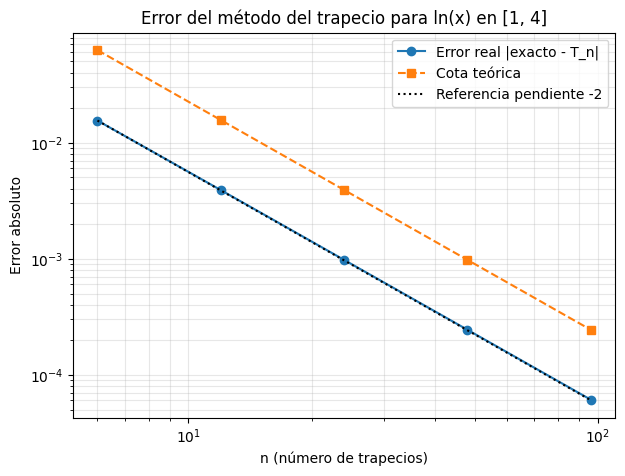

In [ ]:
xs = np.linspace(1, 4, 100001)            # malla muy fina del intervalo [1, 4] para buscar el máximo
M = np.max(np.abs(-1 / xs**2))            # máximo de |f''(x)| = |-1/x^2| en [1, 4] (se alcanza en x = 1)
print(f"max |f''(x)| en [1, 4] = {M:.4f}")   # muestra el máximo calculado (debe ser 1)

cotas = [(b - a)**3 / (12 * k**2) * M for k in ns]   # cota teórica (b-a)^3/(12 n^2)*M para cada n

tabla_h = pd.DataFrame({                  # tabla que compara el error real con la cota
    'n': ns,                              # columna de n
    'Error real': errores,                # error absoluto obtenido en 2 g)
    'Cota teórica': cotas,                # cota teórica del error
    'Cota >= Error': [c >= e for c, e in zip(cotas, errores)]   # verifica que la cota se cumple
})
print(tabla_h.to_string(index=False))     # imprime la tabla comparativa

print(f"\nPara n = 6: error real = {errores[0]:.6f} | cota = {cotas[0]:.6f}")   # compara el caso n = 6
print(f"La cota es {cotas[0]/errores[0]:.1f} veces mayor que el error real.")   # cuántas veces se sobreestima

pendiente = np.polyfit(np.log(ns), np.log(errores), 1)[0]   # pendiente de la recta ajustada a log(error) vs log(n)
print(f"Pendiente estimada en el gráfico log-log: {pendiente:.3f}")   # debería rondar -2

plt.figure(figsize=(7, 5))                                  # crea una figura de 7x5 pulgadas
plt.loglog(ns, errores, 'o-', label='Error real |exacto - T_n|')   # error real en escala log-log
plt.loglog(ns, cotas, 's--', label='Cota teórica')          # cota teórica en escala log-log
plt.loglog(ns, errores[0] * (np.array(ns) / ns[0])**(-2.0), 'k:', label='Referencia pendiente -2')  # recta de pendiente -2
plt.xlabel('n (número de trapecios)')                       # etiqueta del eje x
plt.ylabel('Error absoluto')                                # etiqueta del eje y
plt.title('Error del método del trapecio para ln(x) en [1, 4]')   # título del gráfico
plt.grid(True, which='both', alpha=0.3)                     # agrega una grilla suave
plt.legend()                                                # muestra las leyendas
plt.show()                                                  # dibuja el gráfico

## Ejercicio 4 d) – Simulación de la distribución exponencial

El tiempo (en minutos) entre solicitudes a un servidor tiene densidad $f(x)=\tfrac12 e^{-x/2}$ para $x\ge0$ (exponencial con media $2$, es decir `scale=2`).

Valores **teóricos** (resueltos con integrales en los incisos a, b y c):

- $P(1\le X\le 3)=\displaystyle\int_1^3 \tfrac12 e^{-x/2}dx = e^{-1/2}-e^{-3/2}\approx 0{,}3834$
- $P(X>2)=\displaystyle\int_2^\infty \tfrac12 e^{-x/2}dx = e^{-1}\approx 0{,}3679$
- $E[X]=\displaystyle\int_0^\infty x\,\tfrac12 e^{-x/2}dx = 2$

**Simulación:** se generan 100 000 muestras y se estiman:

- la **media** con el promedio de las muestras (ley de los grandes números), y
- las **probabilidades** con *frecuencias relativas*: la fracción de muestras que cumple la condición.

Luego se comparan con los valores teóricos.

      Magnitud  Simulado  Teórico  Error absoluto
          E[X]  1.991940 2.000000        0.008060
P(1 <= X <= 3)  0.384060 0.383400        0.000660
      P(X > 2)  0.367390 0.367879        0.000489


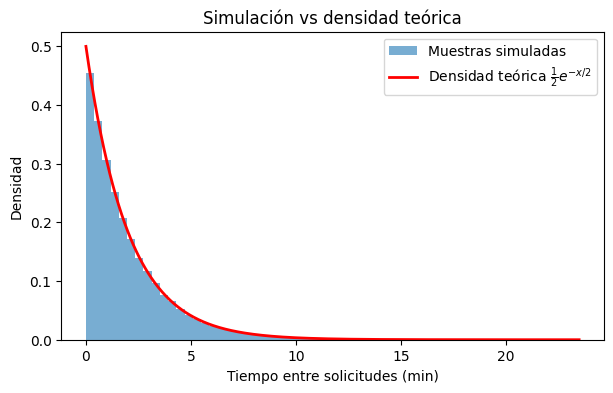

In [ ]:
np.random.seed(42)                                          # fija la semilla para que los resultados sean reproducibles
muestras = np.random.exponential(scale=2, size=100000)      # 100 000 tiempos simulados con media 2

media_sim = muestras.mean()                                 # estimación de E[X]: promedio de las muestras
p_1_3_sim = np.mean((muestras >= 1) & (muestras <= 3))      # frecuencia relativa de 1 <= X <= 3
p_mayor2_sim = np.mean(muestras > 2)                        # frecuencia relativa de X > 2

media_teo = 2                                               # valor teórico de E[X]
p_1_3_teo = np.exp(-1/2) - np.exp(-3/2)                     # valor teórico de P(1 <= X <= 3)
p_mayor2_teo = np.exp(-1)                                   # valor teórico de P(X > 2)

tabla_4d = pd.DataFrame({                                   # tabla comparativa simulación vs teoría
    'Magnitud': ['E[X]', 'P(1 <= X <= 3)', 'P(X > 2)'],     # nombre de cada magnitud
    'Simulado': [media_sim, p_1_3_sim, p_mayor2_sim],       # valores estimados por simulación
    'Teórico': [media_teo, p_1_3_teo, p_mayor2_teo],        # valores exactos
})
tabla_4d['Error absoluto'] = (tabla_4d['Simulado'] - tabla_4d['Teórico']).abs()   # diferencia en valor absoluto
print(tabla_4d.to_string(index=False))                      # imprime la tabla

plt.figure(figsize=(7, 4))                                  # crea la figura
plt.hist(muestras, bins=60, density=True, alpha=0.6, label='Muestras simuladas')   # histograma normalizado como densidad
xx = np.linspace(0, muestras.max(), 500)                    # puntos para dibujar la densidad teórica
plt.plot(xx, 0.5 * np.exp(-xx / 2), 'r', lw=2, label=r'Densidad teórica $\frac{1}{2}e^{-x/2}$')   # curva teórica
plt.xlabel('Tiempo entre solicitudes (min)')                # etiqueta del eje x
plt.ylabel('Densidad')                                      # etiqueta del eje y
plt.title('Simulación vs densidad teórica')                 # título
plt.legend()                                                # leyenda
plt.show()                                                  # muestra el gráfico

## Ejercicio 5 – Integrar lo que no tiene primitiva elemental

La función $e^{-x^2}$ no tiene una antiderivada expresable con funciones elementales, pero igual queremos

$$I=\int_0^1 e^{-x^2}\,dx.$$

### 5 a) Valor de referencia con `erf`

La función error es $\operatorname{erf}(x)=\dfrac{2}{\sqrt\pi}\int_0^x e^{-t^2}dt$, de donde

$$I=\frac{\sqrt\pi}{2}\,\operatorname{erf}(1).$$

SciPy ya la tiene implementada con alta precisión, así que este valor se usa como **referencia exacta** para medir errores.

In [ ]:
I_ref = (np.sqrt(np.pi) / 2) * erf(1)     # I = (raíz de pi / 2) * erf(1): valor de referencia de la integral
print(f"I (valor de referencia) = {I_ref:.10f}")   # muestra el valor con 10 decimales

I (valor de referencia) = 0.7468241328


### 5 c) Integración Monte Carlo

Si $U_1,\dots,U_N$ son variables independientes uniformes en $[0,1]$, entonces $E\!\left[e^{-U^2}\right]=\int_0^1 e^{-x^2}dx=I$, y por la ley de los grandes números

$$I \approx \frac1N\sum_{k=1}^N e^{-U_k^2}.$$

Se implementa el estimador para $N=10^2,10^3,10^4,10^5,10^6$ y se grafica el error en escala log-log.

**Observación:** el error de una sola corrida es aleatorio (a veces cae por suerte muy cerca del valor real). Por eso, además de una corrida única, se repite el experimento **50 veces** para cada $N$ y se promedia el error, lo que muestra la tendencia con más claridad. Se espera que el error decrezca como $1/\sqrt{N}$, es decir, con **pendiente $-1/2$** en el gráfico log-log.

      N  Estimación (1 corrida)  Error (1 corrida)  Error promedio (50 corridas)
    100                0.765061           0.018237                      0.014910
   1000                0.748262           0.001438                      0.005166
  10000                0.750142           0.003317                      0.001460
 100000                0.746744           0.000080                      0.000473
1000000                0.746648           0.000176                      0.000194

Pendiente estimada (error promedio): -0.481  (teórica: -0.5)


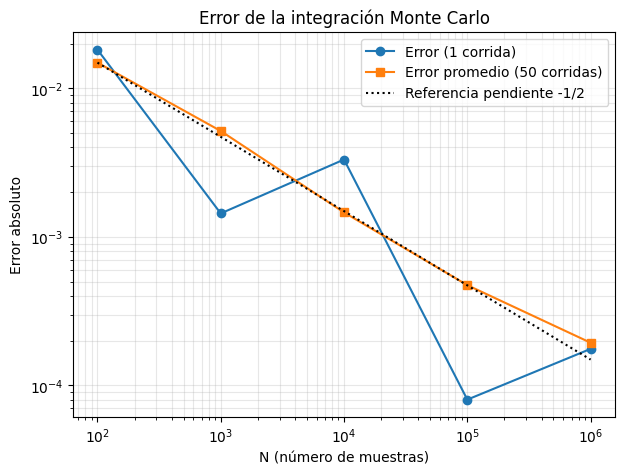

In [ ]:
def monte_carlo(N):
    '''Estima I = integral de exp(-x^2) en [0, 1] con N puntos uniformes.'''
    U = np.random.uniform(0, 1, N)        # genera N números uniformes independientes en [0, 1]
    return np.mean(np.exp(-U**2))         # promedio de exp(-U^2): es el estimador de Monte Carlo

np.random.seed(42)                        # fija la semilla para reproducibilidad
Ns = [10**2, 10**3, 10**4, 10**5, 10**6]  # tamaños de muestra pedidos
reps = 50                                 # cantidad de repeticiones para promediar el error

estimaciones = [monte_carlo(N) for N in Ns]                  # una corrida única para cada N
errores_1 = [abs(est - I_ref) for est in estimaciones]       # error absoluto de esa corrida única
# error absoluto promedio sobre 'reps' corridas independientes para cada N
errores_prom = [np.mean([abs(monte_carlo(N) - I_ref) for _ in range(reps)]) for N in Ns]

tabla_5c = pd.DataFrame({                 # tabla de resultados
    'N': Ns,                              # tamaño de muestra
    'Estimación (1 corrida)': estimaciones,   # estimador de Monte Carlo
    'Error (1 corrida)': errores_1,       # error de la corrida única
    'Error promedio (50 corridas)': errores_prom   # error promedio de las repeticiones
})
print(tabla_5c.to_string(index=False))    # imprime la tabla

pend_prom = np.polyfit(np.log(Ns), np.log(errores_prom), 1)[0]   # pendiente log-log del error promedio
print(f"\nPendiente estimada (error promedio): {pend_prom:.3f}  (teórica: -0.5)")   # compara con -1/2

plt.figure(figsize=(7, 5))                                       # crea la figura
plt.loglog(Ns, errores_1, 'o-', label='Error (1 corrida)')       # error de una corrida, escala log-log
plt.loglog(Ns, errores_prom, 's-', label='Error promedio (50 corridas)')   # error promedio, escala log-log
ref = errores_prom[0] * (np.array(Ns) / Ns[0])**(-0.5)           # recta de referencia con pendiente -1/2
plt.loglog(Ns, ref, 'k:', label='Referencia pendiente -1/2')     # dibuja la recta de referencia
plt.xlabel('N (número de muestras)')                             # etiqueta del eje x
plt.ylabel('Error absoluto')                                     # etiqueta del eje y
plt.title('Error de la integración Monte Carlo')                 # título
plt.grid(True, which='both', alpha=0.3)                          # grilla
plt.legend()                                                     # leyenda
plt.show()                                                       # muestra el gráfico

## Conclusiones

- **Trapecio (ej. 2):** el error decrece como $1/n^2$: al duplicar $n$ se divide aproximadamente por 4 y la pendiente log-log es cercana a $-2$. La cota teórica se cumple siempre, aunque es conservadora (sobreestima el error real). Como $\ln x$ es cóncava, $T_n$ **subestima** el área.
- **Simulación (ej. 4 d):** con 100 000 muestras, las frecuencias relativas y el promedio aproximan muy bien los valores teóricos obtenidos con integrales.
- **Monte Carlo (ej. 5 c):** el error decrece como $1/\sqrt{N}$ (pendiente $\approx -1/2$), mucho más lento que el trapecio en una dimensión. Su ventaja es que esa tasa **no depende de la dimensión** del problema, por lo que resulta especialmente útil en integrales de muchas variables (estadística bayesiana, aprendizaje automático), donde los métodos de malla como el trapecio se vuelven inviables.

---
*Alumno: Crescente Cristhian Mauricio*

*DNI: 35564222*